In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import squarify

In [2]:
# 01: Read the dataset
df = pd.read_csv("age_salary_hours.csv")

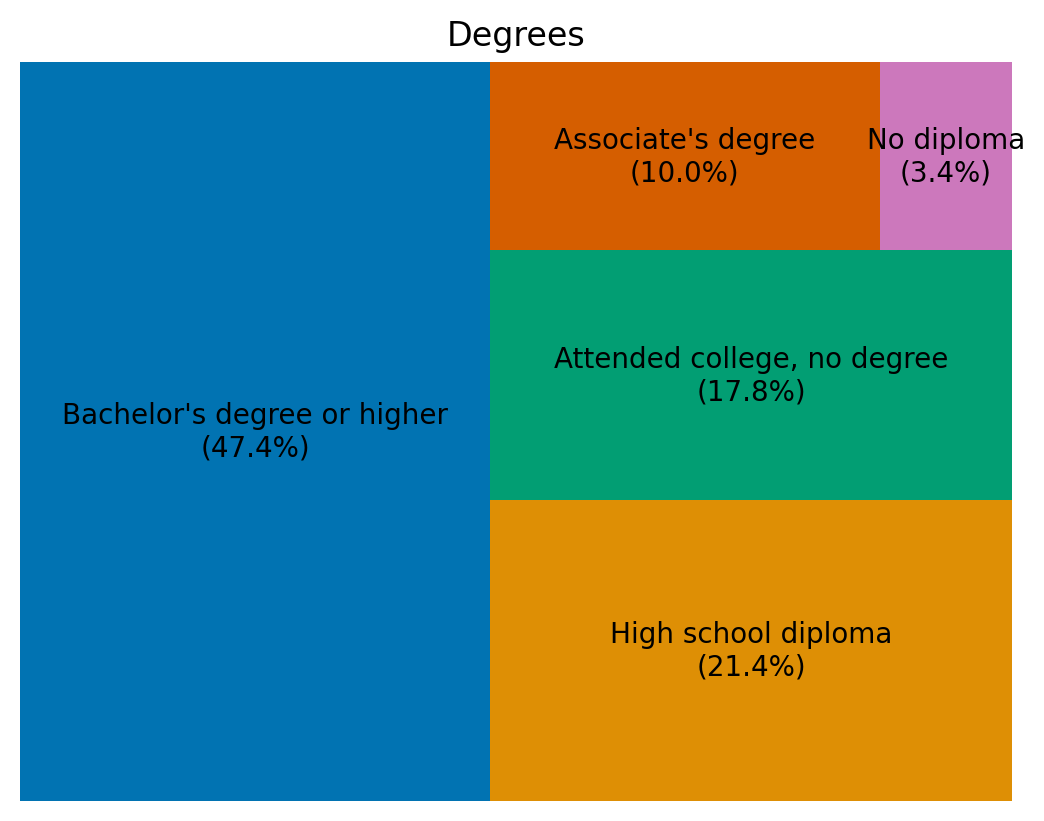

In [6]:
# 02: Tree map for education percentages
education_counts = df['Education'].value_counts()
education_percentages = (education_counts / len(df) * 100).round(1)

# Build labels like: "Bachelor's degree or higher (47.4%)"
labels = [
    f"{edu}\n({pct}%)"
    for edu, pct in zip(education_percentages.index, education_percentages.values)
]

plt.figure(dpi=200)
squarify.plot(
    sizes=education_percentages.values,
    label=labels,
    color=sns.color_palette("colorblind", len(education_percentages))
)
plt.axis('off')
plt.title('Degrees')
plt.show()

C:\Users\86158\AppData\Local\Temp\ipykernel_5724\1149324741.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
C:\Users\86158\AppData\Local\Temp\ipykernel_5724\1149324741.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


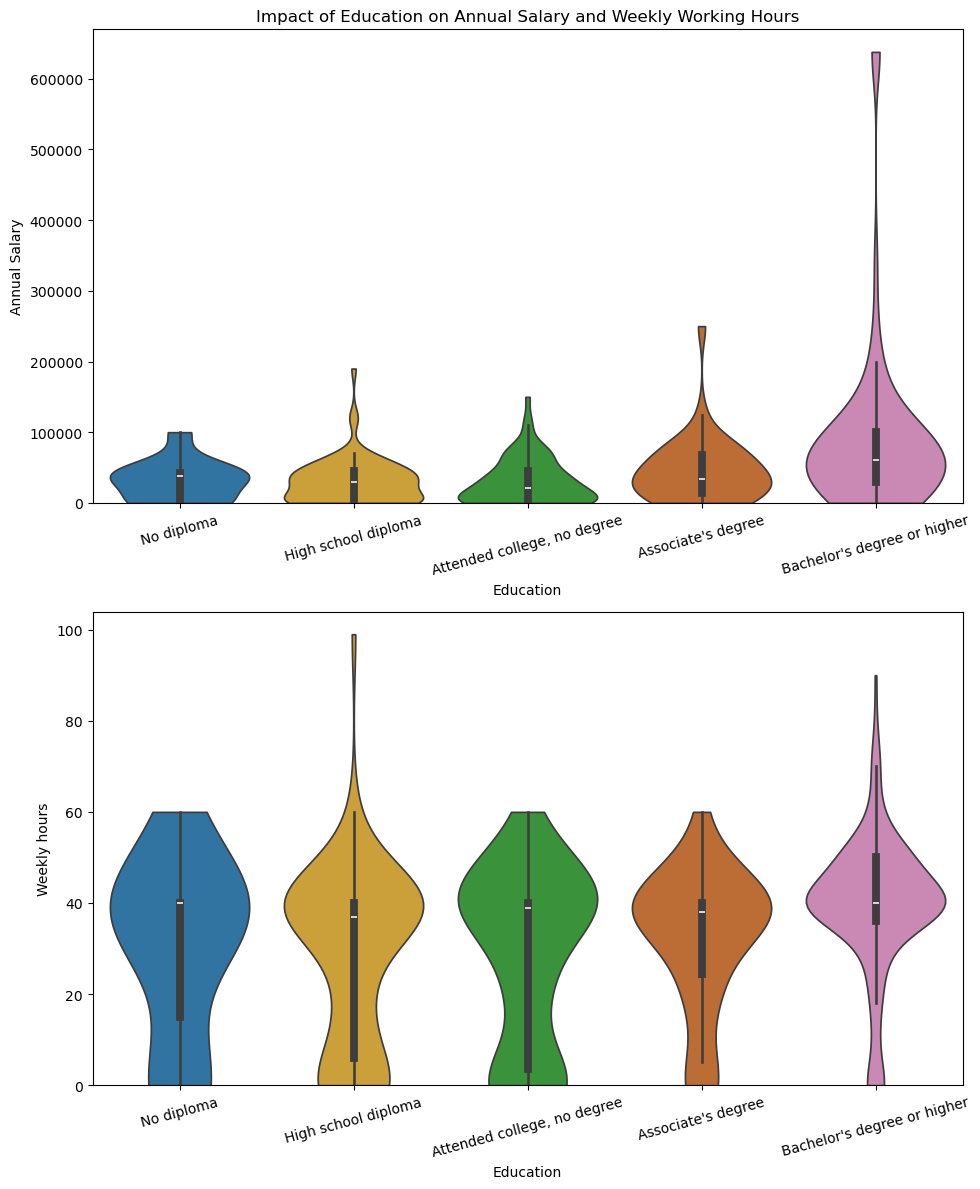

In [8]:
# 03: 绘制小提琴图 (Violin plots)
# 过滤掉 65 岁及以上的人
df_under65 = df[df['Age'] < 65]

# 定义学历的自然顺序（从低到高），以匹配目标图
edu_order = [
    'No diploma',
    'High school diploma',
    'Attended college, no degree',
    "Associate's degree",
    "Bachelor's degree or higher"
]

# 为每个学历指定颜色，完全匹配目标图
color_dict = {
    'No diploma': '#1f77b4',                     # 蓝色
    'High school diploma': '#e3aa23',            # 黄色
    'Attended college, no degree': '#2ca02c',    # 绿色
    "Associate's degree": '#d2691e',             # 棕色
    "Bachelor's degree or higher": '#d47eb8'     # 粉色
}

# 创建 2 行 1 列的子图
fig, axes = plt.subplots(2, 1, figsize=(10, 12))

# 顶部子图：年薪与教育背景的关系
sns.violinplot(
    data=df_under65,
    x='Education',
    y='Annual Salary',
    order=edu_order,       # 强制按照自然顺序排列
    palette=color_dict,    # 使用自定义颜色
    cut=0,                 # 截断核密度估计的尾部，防止超出数据范围
    ax=axes[0]
)
axes[0].set_title('Impact of Education on Annual Salary and Weekly Working Hours')
axes[0].set_xlabel('Education')
axes[0].set_ylabel('Annual Salary')
axes[0].set_ylim(bottom=0) # 强制 Y 轴从 0 开始，消除负数区域
axes[0].tick_params(axis='x', rotation=15)

# 底部子图：每周工作时间与教育背景的关系
sns.violinplot(
    data=df_under65,
    x='Education',
    y='Weekly hours',
    order=edu_order,
    palette=color_dict,
    cut=0,
    ax=axes[1]
)
axes[1].set_xlabel('Education')
axes[1].set_ylabel('Weekly hours')
axes[1].set_ylim(bottom=0) # 强制 Y 轴从 0 开始
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()